In [1]:

import os, sys, time
print("=== SHELFSENSE LITE 11% — FINAL EVALUATION v3 BOOT ===", flush=True)
print("[BOOT] Python:", sys.version, flush=True)
print("[BOOT] cwd:", os.getcwd(), flush=True)
print("[BOOT] heartbeat 1", flush=True); time.sleep(1)
print("[BOOT] heartbeat 2", flush=True)
open("/kaggle/working/SHELFSENSE_FINAL_V3_STARTED.txt","w").write("started\n")
print("=== HEARTBEAT OK ===", flush=True)


=== SHELFSENSE LITE 11% — FINAL EVALUATION v3 BOOT ===
[BOOT] Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[BOOT] cwd: /kaggle/working
[BOOT] heartbeat 1
[BOOT] heartbeat 2
=== HEARTBEAT OK ===



# 11% — ShelfSense Lite
## Notebook 2/2 — Final Evaluation v3 (Runtime-Safe)

This notebook performs **no retraining**. It uses the already-trained YOLO11s champion from:

```text
/kaggle/input/datasets/wafabila/checkpoint-retrain
```

and the canonical SKU-110K source:

```text
/kaggle/input/datasets/wafabila/sku110k/SKU110K_fixed
```

### What v3 fixes

The previous run successfully completed checkpoint loading, dataset audit, conversion, training-history plots, final validation, and official test detection. It stopped only when starting the extra counting inference pass.

There was **no Python traceback** at that point. v3 keeps the same evaluation protocol but makes counting runtime-safe:

- base confidence starts at `0.10` because the candidate grid also starts at `0.10`;
- inference runs in chunks of 64 images;
- CUDA half precision is enabled when available;
- progress is printed every chunk;
- unreadable images are skipped and recorded;
- intermediate counting state is written immediately.

### Scope

ShelfSense Lite is a **single-class dense retail-product detector**. It localizes visible products and derives a visible-product count from detections. It is not SKU recognition, brand recognition, or hidden-inventory estimation.


In [2]:

import importlib.util, subprocess, sys
need=[]
if importlib.util.find_spec("ultralytics") is None: need.append("ultralytics>=8.4.0")
if importlib.util.find_spec("yaml") is None: need.append("pyyaml")
if need:
    print("[SETUP] Installing:", need, flush=True)
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*need])
print("[SETUP] dependencies OK", flush=True)


[SETUP] Installing: ['ultralytics>=8.4.0']
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.5 MB/s eta 0:00:00
[SETUP] dependencies OK


In [3]:

from pathlib import Path
import os, json, random, shutil, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps
import torch
from ultralytics import YOLO

SEED=42
random.seed(SEED); np.random.seed(SEED)

DATA_ROOT=Path("/kaggle/input/datasets/wafabila/sku110k/SKU110K_fixed")
CHECKPOINT_ROOT=Path("/kaggle/input/datasets/wafabila/checkpoint-retrain")
BEST_PT=CHECKPOINT_ROOT/"shelfsense_yolo11s_best.pt"
RESULTS_CSV=CHECKPOINT_ROOT/"results.csv"
ARGS_YAML=CHECKPOINT_ROOT/"args.yaml"
ANN_DIR=DATA_ROOT/"annotations"; IMG_DIR=DATA_ROOT/"images"

WORK=Path("/kaggle/working/shelfsense_11pct_final_v3")
DS=WORK/"dataset_yolo"; REPORT=WORK/"reports"; RUNS=WORK/"runs"; MODEL_DIR=WORK/"models"
ASSET_DATA=WORK/"assets"/"dataset"; ASSET_TRAIN=WORK/"assets"/"training"; ASSET_EVAL=WORK/"assets"/"evaluation"; ASSET_PRED=WORK/"assets"/"predictions"
for p in [WORK,DS,REPORT,RUNS,MODEL_DIR,ASSET_DATA,ASSET_TRAIN,ASSET_EVAL,ASSET_PRED]: p.mkdir(parents=True,exist_ok=True)

DEVICE=0 if torch.cuda.is_available() else "cpu"
print("[CONFIG] device:", DEVICE)
if torch.cuda.is_available(): print("[CONFIG] GPU:", torch.cuda.get_device_name(0))
for p in [DATA_ROOT,CHECKPOINT_ROOT,ANN_DIR,IMG_DIR,BEST_PT,RESULTS_CSV,ARGS_YAML]: assert p.exists(), p
print("=== INPUT CHECK PASSED ===")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
[CONFIG] device: 0
[CONFIG] GPU: Tesla T4
=== INPUT CHECK PASSED ===



## 1. Load the trained champion

This notebook never calls `model.train(...)`.


In [4]:

print("[MODEL] checkpoint MB:", BEST_PT.stat().st_size/1024/1024)
model=YOLO(str(BEST_PT))
FINAL_MODEL=MODEL_DIR/"shelfsense_yolo11s_best.pt"
shutil.copy2(BEST_PT,FINAL_MODEL)
print("[MODEL] loaded:",BEST_PT)


[MODEL] checkpoint MB: 18.302026748657227
[MODEL] loaded: /kaggle/input/datasets/wafabila/checkpoint-retrain/shelfsense_yolo11s_best.pt



## 2. Audit SKU-110K and rebuild the clean YOLO representation

The official train/validation/test split is preserved. Only objectively invalid rows are dropped.


In [5]:

img_files=[p for p in IMG_DIR.iterdir() if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}]
available={p.name:p for p in img_files}
COLS=["image","x1","y1","x2","y2","source_class","image_width","image_height"]
csvs={"train":ANN_DIR/"annotations_train.csv","val":ANN_DIR/"annotations_val.csv","test":ANN_DIR/"annotations_test.csv"}
frames={s:pd.read_csv(p,names=COLS,header=None) for s,p in csvs.items()}
expected={"train":8219,"val":588,"test":2936}
for s,n in expected.items():
    print(f"[{s}] rows={len(frames[s]):,} images={frames[s]['image'].nunique():,}")
    assert int(frames[s]["image"].nunique())==n
assert len(img_files)==11743


[train] rows=1,208,482 images=8,219
[val] rows=90,968 images=588
[test] rows=431,546 images=2,936


In [6]:

audit={}; density=[]; bad_parts=[]
for split,df in frames.items():
    num=df[["x1","y1","x2","y2","image_width","image_height"]].apply(pd.to_numeric,errors="coerce")
    bad_nan=num.isna().any(axis=1)
    bad_geom=(num["x2"]<=num["x1"])|(num["y2"]<=num["y1"])
    bad_bounds=(num["x1"]<0)|(num["y1"]<0)|(num["x2"]>num["image_width"])|(num["y2"]>num["image_height"])
    missing=~df["image"].astype(str).isin(available.keys())
    bad=bad_nan|bad_geom|bad_bounds|missing
    counts=df.loc[~bad].groupby("image").size()
    density.append({"split":split,"images":int(df["image"].nunique()),"raw_boxes":int(len(df)),"valid_boxes":int((~bad).sum()),"invalid_rows":int(bad.sum()),"mean_objects":float(counts.mean()),"median_objects":float(counts.median()),"min_objects":int(counts.min()),"max_objects":int(counts.max())})
    audit[split]={"images":int(df["image"].nunique()),"raw_rows":int(len(df)),"valid_rows":int((~bad).sum()),"invalid_rows":int(bad.sum())}
    if bad.any():
        x=df.loc[bad].copy(); x["split"]=split; bad_parts.append(x)

density_df=pd.DataFrame(density); display(density_df)
bad_df=pd.concat(bad_parts,ignore_index=True) if bad_parts else pd.DataFrame()
bad_df.to_csv(REPORT/"invalid_annotation_rows.csv",index=False)
(REPORT/"source_audit.json").write_text(json.dumps(audit,indent=2))


,split,images,raw_boxes,valid_boxes,invalid_rows,mean_objects,median_objects,min_objects,max_objects
0,train,8219,1208482,1193564,14918,145.220100,136.0,1,575
1,val,588,90968,89937,1031,152.954082,137.0,40,718
2,test,2936,431546,426335,5211,145.209469,136.0,18,533


338

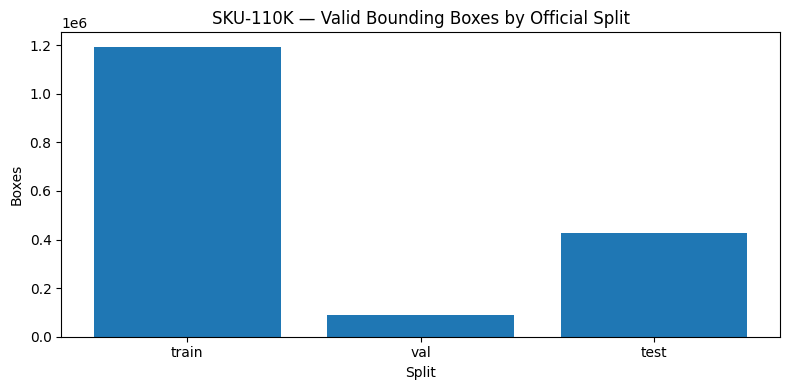

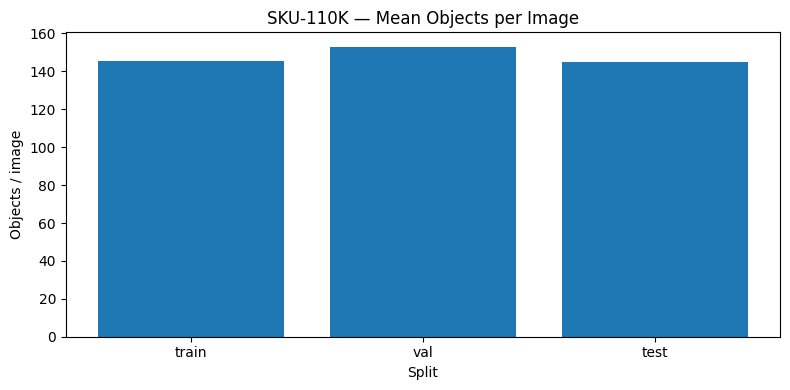

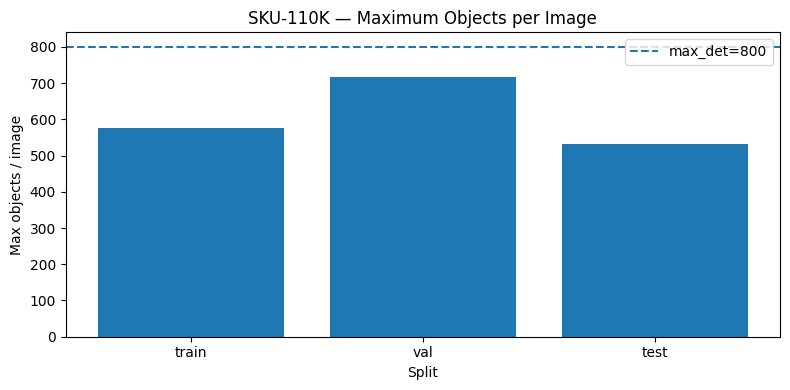

In [7]:

for col,title,file,ylabel in [
    ("valid_boxes","Valid Bounding Boxes by Official Split","boxes_by_split.png","Boxes"),
    ("mean_objects","Mean Objects per Image","mean_objects_per_image.png","Objects / image"),
    ("max_objects","Maximum Objects per Image","max_objects_per_image.png","Max objects / image")]:
    plt.figure(figsize=(8,4)); plt.bar(density_df["split"],density_df[col])
    if col=="max_objects": plt.axhline(800,ls="--",label="max_det=800"); plt.legend()
    plt.title("SKU-110K — "+title); plt.xlabel("Split"); plt.ylabel(ylabel); plt.tight_layout()
    plt.savefig(ASSET_DATA/file,dpi=180,bbox_inches="tight"); plt.show()


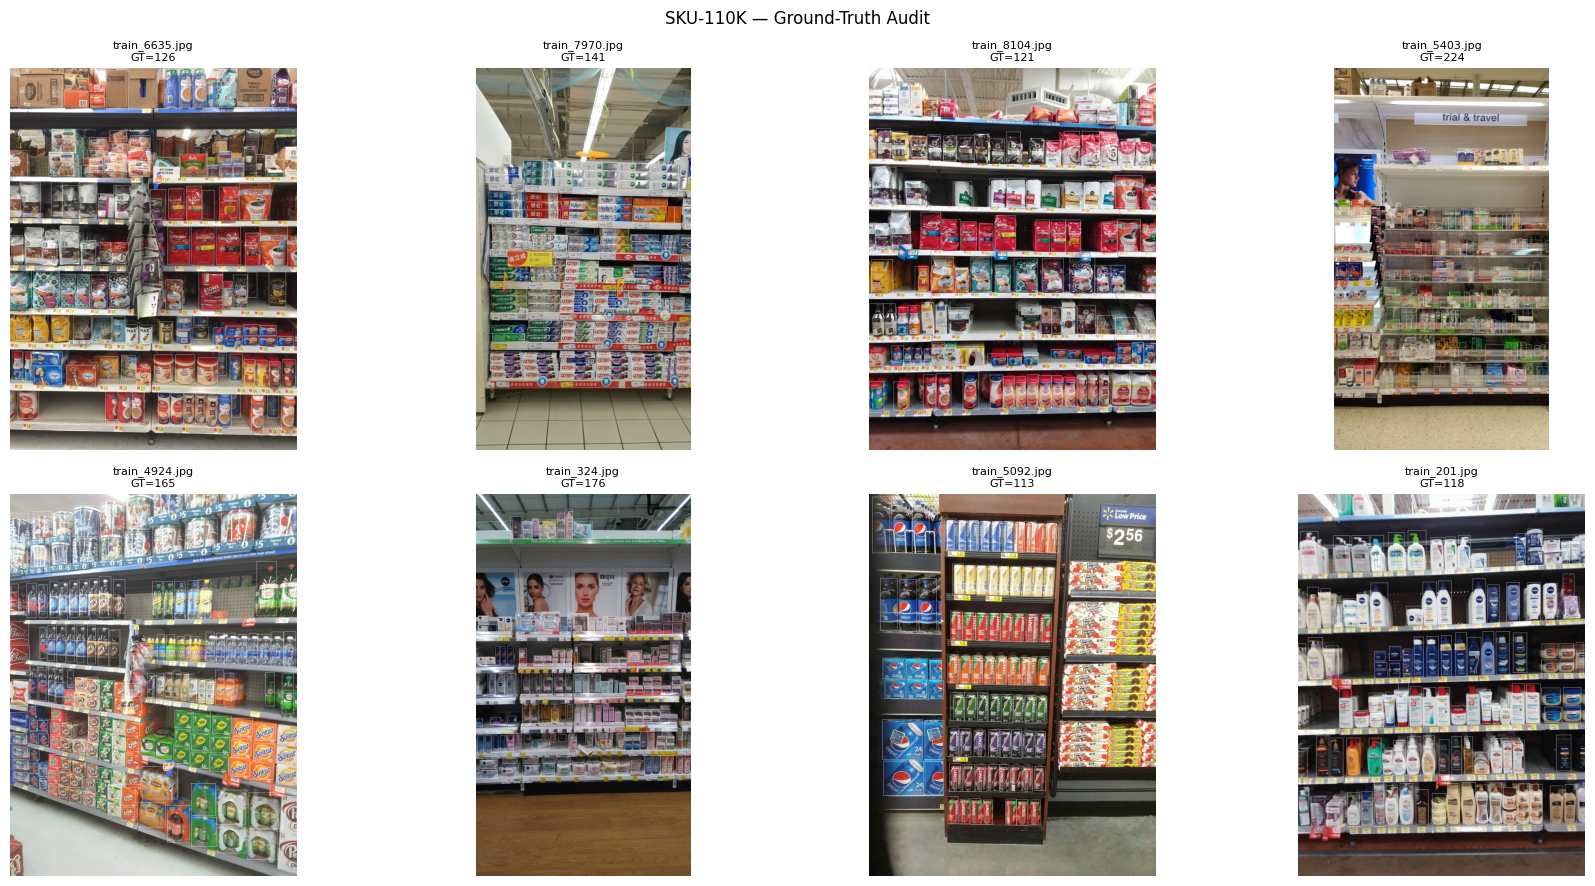

In [8]:

def draw_gt(split,image_name):
    rows=frames[split][frames[split]["image"].astype(str)==str(image_name)]
    im=ImageOps.exif_transpose(Image.open(available[str(image_name)])).convert("RGB")
    dr=ImageDraw.Draw(im); n=0
    for _,r in rows.iterrows():
        try:
            x1,y1,x2,y2=map(float,[r.x1,r.y1,r.x2,r.y2]); w,h=float(r.image_width),float(r.image_height)
        except Exception: continue
        if x2>x1 and y2>y1 and x1>=0 and y1>=0 and x2<=w and y2<=h:
            dr.rectangle([x1,y1,x2,y2],width=2); n+=1
    return im,n

names=frames["train"]["image"].drop_duplicates().sample(8,random_state=SEED).astype(str).tolist()
fig,axes=plt.subplots(2,4,figsize=(18,9))
for ax,name in zip(axes.flat,names):
    im,n=draw_gt("train",name); ax.imshow(im); ax.set_title(f"{name}\nGT={n}",fontsize=8); ax.axis("off")
plt.suptitle("SKU-110K — Ground-Truth Audit"); plt.tight_layout(); plt.savefig(ASSET_DATA/"ground_truth_grid.png",dpi=170,bbox_inches="tight"); plt.show()


In [9]:

if DS.exists(): shutil.rmtree(DS)
for s in ["train","val","test"]:
    (DS/"images"/s).mkdir(parents=True,exist_ok=True); (DS/"labels"/s).mkdir(parents=True,exist_ok=True)
conversion={}
for split,df0 in frames.items():
    df=df0.copy()
    for c in ["x1","y1","x2","y2","image_width","image_height"]: df[c]=pd.to_numeric(df[c],errors="coerce")
    valid=(df[["x1","y1","x2","y2","image_width","image_height"]].notna().all(axis=1)&(df["x2"]>df["x1"])&(df["y2"]>df["y1"])&(df["x1"]>=0)&(df["y1"]>=0)&(df["x2"]<=df["image_width"])&(df["y2"]<=df["image_height"])&df["image"].astype(str).isin(available.keys()))
    clean=df.loc[valid].copy(); ni=nbx=0
    for image_name,g in clean.groupby("image",sort=False):
        src=available[str(image_name)]; dst=DS/"images"/split/src.name
        if not dst.exists(): os.symlink(src,dst)
        lines=[]
        for _,r in g.iterrows():
            w,h=float(r.image_width),float(r.image_height)
            xc=((float(r.x1)+float(r.x2))/2)/w; yc=((float(r.y1)+float(r.y2))/2)/h; bw=(float(r.x2)-float(r.x1))/w; bh=(float(r.y2)-float(r.y1))/h
            lines.append(f"0 {np.clip(xc,0,1):.7f} {np.clip(yc,0,1):.7f} {np.clip(bw,1e-8,1):.7f} {np.clip(bh,1e-8,1):.7f}")
        (DS/"labels"/split/src.stem).with_suffix(".txt").write_text("\n".join(lines)+"\n")
        ni+=1; nbx+=len(lines)
    conversion[split]={"images":ni,"boxes":nbx,"dropped_rows":int((~valid).sum())}
print(json.dumps(conversion,indent=2)); (REPORT/"conversion_summary.json").write_text(json.dumps(conversion,indent=2))
data_yaml=WORK/"sku110k.yaml"; data_yaml.write_text(yaml.safe_dump({"path":str(DS),"train":"images/train","val":"images/val","test":"images/test","nc":1,"names":["object"]},sort_keys=False))


{
  "train": {
    "images": 8219,
    "boxes": 1193564,
    "dropped_rows": 14918
  },
  "val": {
    "images": 588,
    "boxes": 89937,
    "dropped_rows": 1031
  },
  "test": {
    "images": 2936,
    "boxes": 426335,
    "dropped_rows": 5211
  }
}


137

In [10]:

def check_split(split):
    bad=boxes=0; labels=list((DS/"labels"/split).glob("*.txt")); images=list((DS/"images"/split).iterdir())
    for lp in labels:
        for line in lp.read_text().splitlines():
            if not line.strip(): continue
            p=line.split()
            if len(p)!=5: bad+=1; continue
            try:
                cls,x,y,w,h=map(float,p); ok=cls==0 and 0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1
                if not ok: bad+=1
                boxes+=1
            except Exception: bad+=1
    return {"images":len(images),"labels":len(labels),"boxes":boxes,"bad_label_lines":bad}
converted={s:check_split(s) for s in ["train","val","test"]}; print(json.dumps(converted,indent=2)); assert sum(v["bad_label_lines"] for v in converted.values())==0
(REPORT/"converted_dataset_audit.json").write_text(json.dumps(converted,indent=2))


{
  "train": {
    "images": 8219,
    "labels": 8219,
    "boxes": 1193564,
    "bad_label_lines": 0
  },
  "val": {
    "images": 588,
    "labels": 588,
    "boxes": 89937,
    "bad_label_lines": 0
  },
  "test": {
    "images": 2936,
    "labels": 2936,
    "boxes": 426335,
    "bad_label_lines": 0
  }
}


309


## 3. Recover training-history evidence

Training is not repeated. Curves are reconstructed from the `results.csv` produced by Notebook 1.


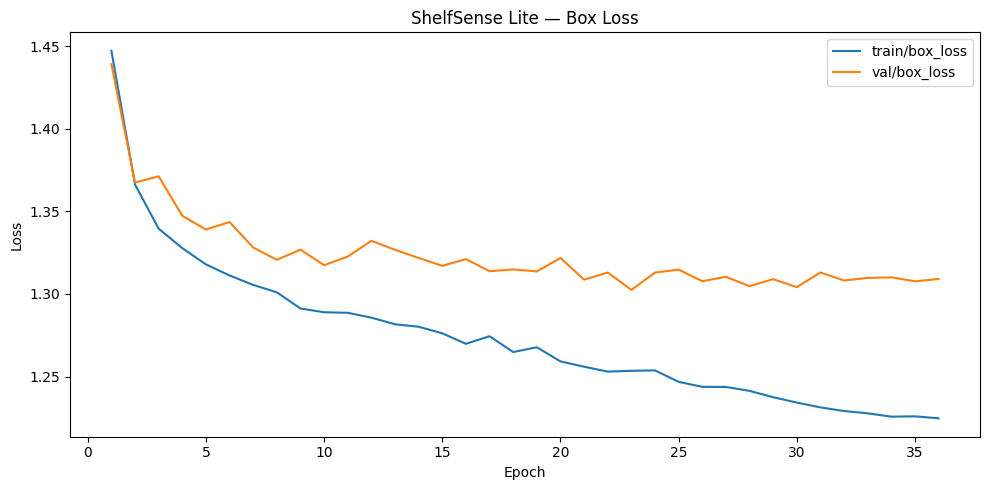

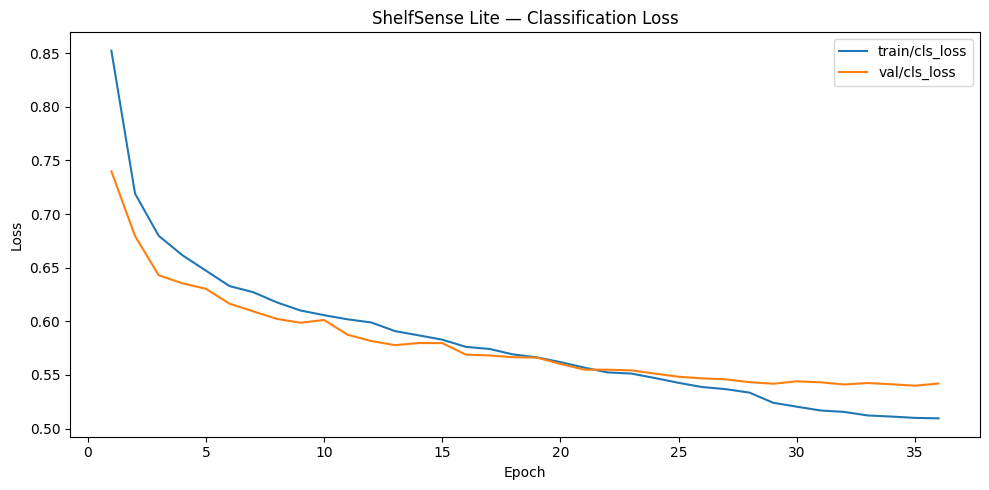

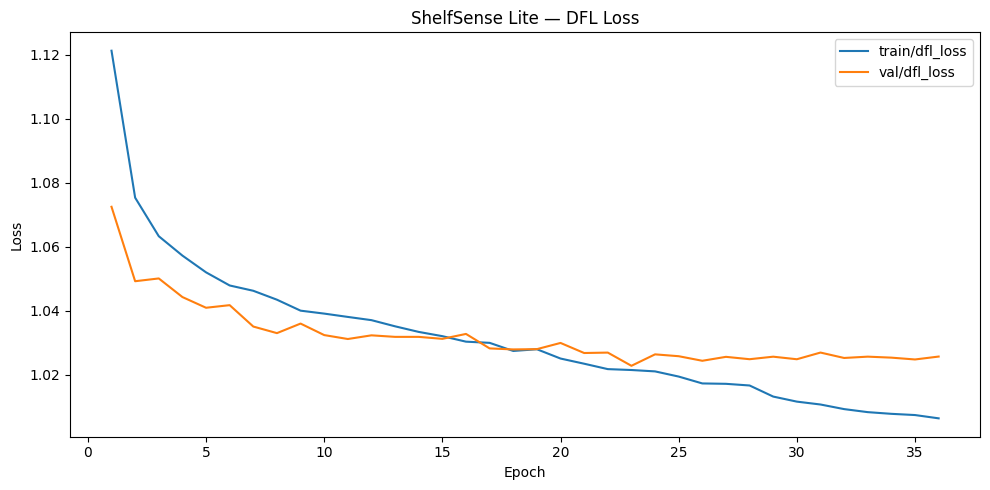

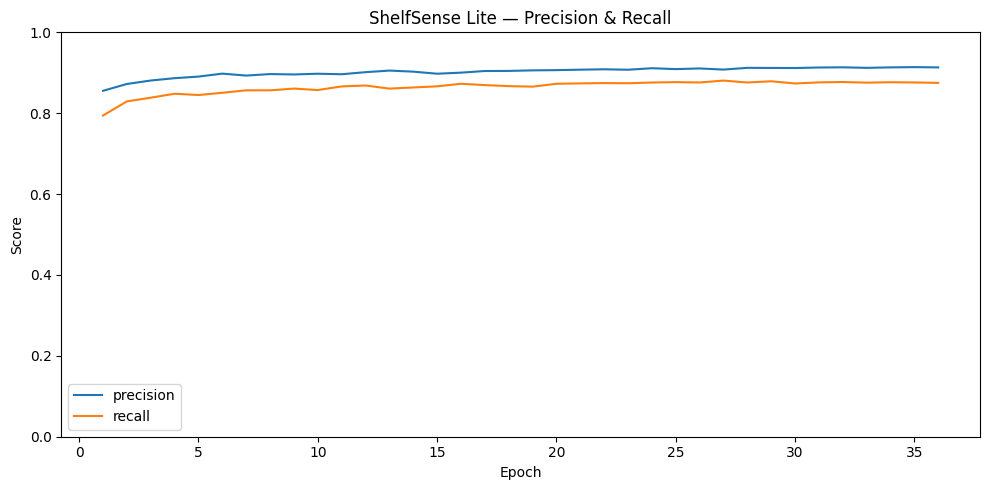

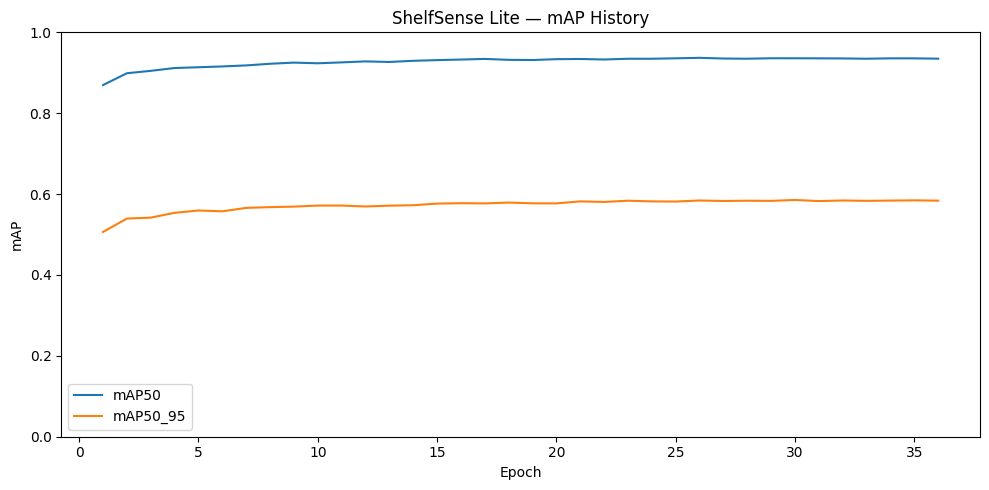

{
  "best_epoch": 30,
  "epochs_completed": 36,
  "precision": 0.91177,
  "recall": 0.87349,
  "mAP50": 0.93585,
  "mAP50_95": 0.58545
}


In [11]:

history=pd.read_csv(RESULTS_CSV); history.columns=[c.strip() for c in history.columns]; history.to_csv(REPORT/"training_history.csv",index=False)
epoch=np.arange(1,len(history)+1)
for cols,title,file in [(["train/box_loss","val/box_loss"],"Box Loss","box_loss_curve.png"),(["train/cls_loss","val/cls_loss"],"Classification Loss","cls_loss_curve.png"),(["train/dfl_loss","val/dfl_loss"],"DFL Loss","dfl_loss_curve.png")]:
    plt.figure(figsize=(10,5))
    for c in cols:
        if c in history.columns: plt.plot(epoch,history[c],label=c)
    plt.title("ShelfSense Lite — "+title); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.tight_layout(); plt.savefig(ASSET_TRAIN/file,dpi=180,bbox_inches="tight"); plt.show()
metric_cols={}
for k,cands in {"precision":["metrics/precision(B)","metrics/precision"],"recall":["metrics/recall(B)","metrics/recall"],"mAP50":["metrics/mAP50(B)","metrics/mAP50"],"mAP50_95":["metrics/mAP50-95(B)","metrics/mAP50-95"]}.items():
    for c in cands:
        if c in history.columns: metric_cols[k]=c; break
plt.figure(figsize=(10,5))
for k in ["precision","recall"]: plt.plot(epoch,history[metric_cols[k]],label=k)
plt.title("ShelfSense Lite — Precision & Recall"); plt.xlabel("Epoch"); plt.ylabel("Score"); plt.ylim(0,1); plt.legend(); plt.tight_layout(); plt.savefig(ASSET_TRAIN/"precision_recall_history.png",dpi=180,bbox_inches="tight"); plt.show()
plt.figure(figsize=(10,5))
for k in ["mAP50","mAP50_95"]: plt.plot(epoch,history[metric_cols[k]],label=k)
plt.title("ShelfSense Lite — mAP History"); plt.xlabel("Epoch"); plt.ylabel("mAP"); plt.ylim(0,1); plt.legend(); plt.tight_layout(); plt.savefig(ASSET_TRAIN/"map_history.png",dpi=180,bbox_inches="tight"); plt.show()
best_idx=int(history[metric_cols["mAP50_95"]].idxmax()); best_summary={"best_epoch":best_idx+1,"epochs_completed":len(history)}
for k,c in metric_cols.items(): best_summary[k]=float(history.iloc[best_idx][c])
(REPORT/"best_epoch_summary.json").write_text(json.dumps(best_summary,indent=2)); print(json.dumps(best_summary,indent=2))



## 4. Final detection benchmark

Both validation and official held-out test use `imgsz=960` and `max_det=800`. `plots=True` preserves PR/F1/confusion assets.


In [12]:

val_metrics=model.val(data=str(data_yaml),split="val",imgsz=960,batch=4,conf=0.001,iou=0.7,max_det=800,device=DEVICE,workers=2,plots=True,project=str(RUNS),name="official_val_maxdet800",exist_ok=True,verbose=True)
val_report={"precision":float(val_metrics.box.mp),"recall":float(val_metrics.box.mr),"mAP50":float(val_metrics.box.map50),"mAP50_95":float(val_metrics.box.map),"max_det":800,"speed_ms":{k:float(v) for k,v in val_metrics.speed.items()}}
(REPORT/"validation_detection_metrics.json").write_text(json.dumps(val_report,indent=2)); print("=== FINAL VALIDATION ==="); print(json.dumps(val_report,indent=2))
for src in Path(val_metrics.save_dir).glob("*.png"): shutil.copy2(src,ASSET_EVAL/f"val_{src.name}")


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 92.9±12.8 MB/s, size: 1177.7 KB)
val: Scanning /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/labels/val... 588 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 588/588 133.6it/s 4.4s
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/val/val_0.jpg: corrupt JPEG restored and saved
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/val/val_115.jpg: corrupt JPEG restored and saved
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/val/val_127.jpg: corrupt JPEG restored and saved
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/val/val_166.jpg: corrupt JPEG restored and saved
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/val/val_172.jpg: corrupt JPEG restored and saved
val: /kag

Corrupt JPEG data: 786 extraneous bytes before marker 0xd9


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 7% ╸─────────── 11/147 7.3it/s 6.5s<18.6s

Corrupt JPEG data: 305 extraneous bytes before marker 0xd9


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 24% ━━╸───────── 36/147 8.4it/s 9.7s<13.2s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 80% ━━━━━━━━━╸── 119/147 7.9it/s 19.1s<3.5s

Corrupt JPEG data: premature end of data segment


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 147/147 6.2it/s 23.8s


Corrupt JPEG data: 786 extraneous bytes before marker 0xd9


                   all        588      89937      0.912      0.874      0.936      0.587
Speed: 1.6ms preprocess, 14.6ms inference, 0.0ms loss, 6.8ms postprocess per image
Results saved to /kaggle/working/shelfsense_11pct_final_v3/runs/official_val_maxdet800
=== FINAL VALIDATION ===
{
  "precision": 0.9119463084161766,
  "recall": 0.8735668457424569,
  "mAP50": 0.9358892967255817,
  "mAP50_95": 0.5866980113205288,
  "max_det": 800,
  "speed_ms": {
    "preprocess": 1.5650236020409694,
    "inference": 14.589159899661094,
    "loss": 0.023230192177803463,
    "postprocess": 6.759091486392022
  }
}


In [13]:

test_metrics=model.val(data=str(data_yaml),split="test",imgsz=960,batch=4,conf=0.001,iou=0.7,max_det=800,device=DEVICE,workers=2,plots=True,project=str(RUNS),name="official_test_maxdet800",exist_ok=True,verbose=True)
test_report={"precision":float(test_metrics.box.mp),"recall":float(test_metrics.box.mr),"mAP50":float(test_metrics.box.map50),"mAP50_95":float(test_metrics.box.map),"max_det":800,"speed_ms":{k:float(v) for k,v in test_metrics.speed.items()}}
(REPORT/"test_detection_metrics.json").write_text(json.dumps(test_report,indent=2)); print("=== OFFICIAL TEST DETECTION ==="); print(json.dumps(test_report,indent=2))
for src in Path(test_metrics.save_dir).glob("*.png"): shutil.copy2(src,ASSET_EVAL/f"test_{src.name}")


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.3 ms, read: 92.3±15.8 MB/s, size: 944.5 KB)
val: Scanning /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/labels/test... 2935 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 2936/2936 135.6it/s 21.6s
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/test/test_1029.jpg: corrupt JPEG restored and saved
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/test/test_1035.jpg: corrupt JPEG restored and saved
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/test/test_1059.jpg: corrupt JPEG restored and saved
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/test/test_1086.jpg: corrupt JPEG restored and saved
val: /kaggle/working/shelfsense_11pct_final_v3/dataset_yolo/images/test/test_1090.jpg: corrupt JPEG restore

Corrupt JPEG data: 935 extraneous bytes before marker 0xd9


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 17% ━━────────── 130/734 8.7it/s 20.7s<1:10

Corrupt JPEG data: 70 extraneous bytes before marker 0xd9


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 19% ━━────────── 146/734 8.7it/s 22.5s<1:07

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 80% ━━━━━━━━━╸── 588/734 6.7it/s 1:14<21.7s

Corrupt JPEG data: 241 extraneous bytes before marker 0xd9


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 82% ━━━━━━━━━╸── 608/734 6.5it/s 1:17<19.3s

Corrupt JPEG data: 555 extraneous bytes before marker 0xd9


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 734/734 7.7it/s 1:36
                   all       2935     426209      0.911      0.882      0.944      0.592
Speed: 1.4ms preprocess, 12.7ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /kaggle/working/shelfsense_11pct_final_v3/runs/official_test_maxdet800
=== OFFICIAL TEST DETECTION ===
{
  "precision": 0.9106692193164472,
  "recall": 0.8819945144283673,
  "mAP50": 0.9435687018998892,
  "mAP50_95": 0.591797545318477,
  "max_det": 800,
  "speed_ms": {
    "preprocess": 1.4232192514481612,
    "inference": 12.70996382043936,
    "loss": 0.003249400680967717,
    "postprocess": 2.2288498739345344
  }
}



## 5. Runtime-safe counting evaluation

The confidence threshold is chosen **only on validation**. Counting uses full official test images that are readable. The minimum base confidence is `0.10`, matching the lowest candidate threshold, so lower-confidence detections are never computed unnecessarily.


In [14]:

def gt_counts(split):
    return {lp.stem+".jpg":sum(1 for x in lp.read_text().splitlines() if x.strip()) for lp in (DS/"labels"/split).glob("*.txt")}
def count_metrics(gt,pred):
    common=sorted(set(gt)&set(pred)); assert common
    y=np.array([gt[n] for n in common],dtype=float); p=np.array([pred[n] for n in common],dtype=float); e=p-y
    return {"n":int(len(common)),"MAE":float(np.mean(np.abs(e))),"RMSE":float(np.sqrt(np.mean(e**2))),"bias":float(np.mean(e)),"mean_gt":float(np.mean(y)),"mean_pred":float(np.mean(p))}
def readable_image_paths(split):
    good=[]; skipped=[]
    for p in sorted((DS/"images"/split).iterdir()):
        try:
            with Image.open(p) as im: im.load()
            good.append(p)
        except Exception as e: skipped.append({"image":p.name,"reason":repr(e)})
    if skipped: pd.DataFrame(skipped).to_csv(REPORT/f"{split}_unreadable_for_counting.csv",index=False)
    print(f"[COUNT] {split}: readable={len(good)} skipped={len(skipped)}",flush=True)
    return good

def predict_confidence_lists(split,base_conf=0.10,chunk_size=64):
    paths=readable_image_paths(split); out={}; use_half=bool(torch.cuda.is_available()); total=(len(paths)+chunk_size-1)//chunk_size
    print(f"[COUNT] predicting {split}: {len(paths)} images | chunks={total}",flush=True)
    for chunk_no,start in enumerate(range(0,len(paths),chunk_size),start=1):
        chunk=paths[start:start+chunk_size]; print(f"[COUNT] {split} chunk {chunk_no}/{total}",flush=True)
        try:
            results=model.predict(source=[str(p) for p in chunk],imgsz=960,conf=base_conf,iou=0.60,max_det=800,device=DEVICE,batch=4,half=use_half,stream=True,verbose=False)
            for p,r in zip(chunk,results):
                out[p.name]=np.empty(0,dtype=np.float32) if r.boxes is None or r.boxes.conf is None else r.boxes.conf.detach().cpu().numpy().astype(np.float32)
        except Exception as chunk_error:
            print("[COUNT][WARN] chunk fallback:",repr(chunk_error),flush=True)
            for p in chunk:
                try:
                    r=model.predict(source=str(p),imgsz=960,conf=base_conf,iou=0.60,max_det=800,device=DEVICE,half=use_half,verbose=False)[0]
                    out[p.name]=np.empty(0,dtype=np.float32) if r.boxes is None or r.boxes.conf is None else r.boxes.conf.detach().cpu().numpy().astype(np.float32)
                except Exception as image_error:
                    print(f"[COUNT][SKIP] {p.name}: {repr(image_error)}",flush=True)
    print(f"[COUNT] {split} complete: {len(out)} predictions",flush=True); return out

val_gt=gt_counts("val"); test_gt=gt_counts("test")


[COUNT] val: readable=588 skipped=0
[COUNT] predicting val: 588 images | chunks=10
[COUNT] val chunk 1/10
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] val chunk 2/10
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] val chunk 3/10
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] val chunk 4/10
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] val chunk 5/10
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] val chunk 6/10
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] val chunk 7/10
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] val chunk 8/10
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUN

,conf,n,MAE,RMSE,bias,mean_gt,mean_pred
4,0.30,588,13.760204,26.542643,0.607143,152.954082,153.561224
5,0.35,588,14.124150,27.841113,-4.491497,152.954082,148.462585
3,0.25,588,14.933673,27.225907,6.079932,152.954082,159.034014
6,0.40,588,15.680272,30.357283,-9.227891,152.954082,143.726190
2,0.20,588,18.277211,31.117973,12.566327,152.954082,165.520408
1,0.15,588,24.613946,39.468730,21.328231,152.954082,174.282313
0,0.10,588,35.715986,54.651322,34.610544,152.954082,187.564626


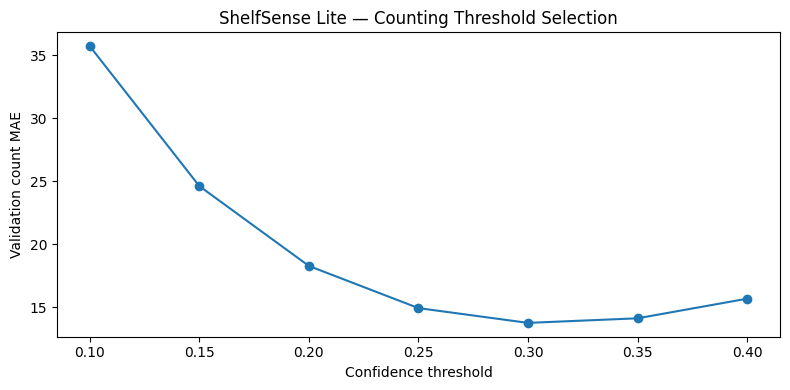

[COUNT] selected confidence: 0.3


In [15]:

val_conf=predict_confidence_lists("val",0.10,64)
rows=[]
for conf in [0.10,0.15,0.20,0.25,0.30,0.35,0.40]:
    pred={name:int(np.sum(scores>=conf)) for name,scores in val_conf.items()}; met=count_metrics(val_gt,pred); rows.append({"conf":conf,**met}); print(conf,met)
threshold_df=pd.DataFrame(rows).sort_values(["MAE","RMSE"]); display(threshold_df); best_conf=float(threshold_df.iloc[0]["conf"])
threshold_df.to_csv(REPORT/"count_threshold_search_validation.csv",index=False)
(REPORT/"counting_stage_state.json").write_text(json.dumps({"validation_predictions":len(val_conf),"selected_confidence":best_conf},indent=2))
ordered=threshold_df.sort_values("conf"); plt.figure(figsize=(8,4)); plt.plot(ordered["conf"],ordered["MAE"],marker="o"); plt.xlabel("Confidence threshold"); plt.ylabel("Validation count MAE"); plt.title("ShelfSense Lite — Counting Threshold Selection"); plt.tight_layout(); plt.savefig(ASSET_EVAL/"count_threshold_search.png",dpi=180,bbox_inches="tight"); plt.show(); print("[COUNT] selected confidence:",best_conf,flush=True)


[COUNT] test: readable=2935 skipped=1
[COUNT] predicting test: 2935 images | chunks=46
[COUNT] test chunk 1/46
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] test chunk 2/46
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] test chunk 3/46
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] test chunk 4/46
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] test chunk 5/46
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] test chunk 6/46
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] test chunk 7/46
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[COUNT] test chunk 8/46
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' in

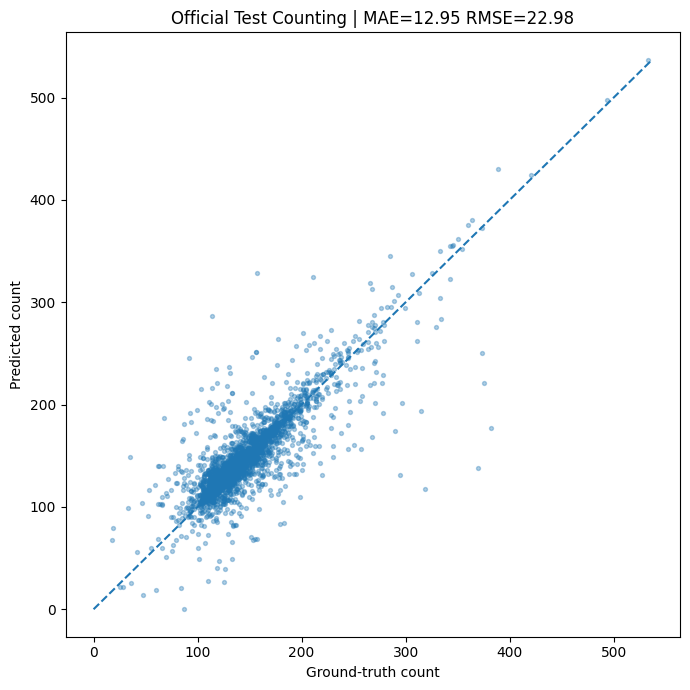

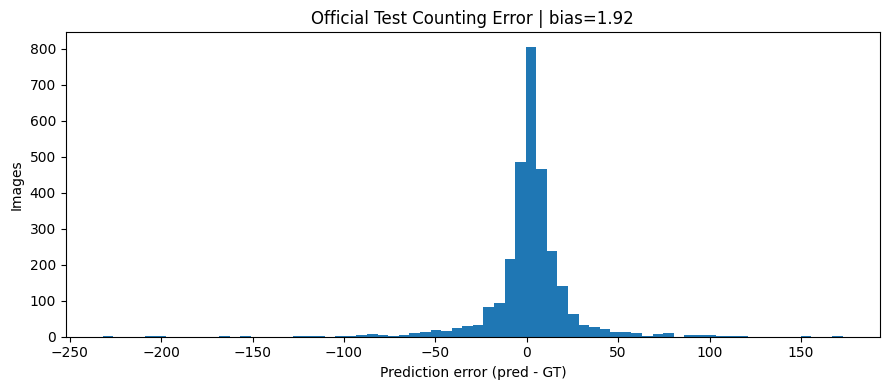

In [16]:

test_conf=predict_confidence_lists("test",0.10,64)
test_pred={name:int(np.sum(scores>=best_conf)) for name,scores in test_conf.items()}; count_test=count_metrics(test_gt,test_pred)
print("=== OFFICIAL TEST COUNTING ==="); print(json.dumps({"confidence":best_conf,**count_test},indent=2))
rows=[]
for name in sorted(set(test_gt)&set(test_pred)):
    gt=test_gt[name]; pr=test_pred[name]; rows.append({"image":name,"gt_count":gt,"pred_count":pr,"error":pr-gt,"abs_error":abs(pr-gt)})
count_df=pd.DataFrame(rows); count_df.to_csv(REPORT/"test_count_predictions.csv",index=False); (REPORT/"test_count_metrics.json").write_text(json.dumps({"confidence":best_conf,**count_test},indent=2)); (REPORT/"counting_stage_complete.json").write_text(json.dumps({"test_predictions":len(test_pred),"confidence":best_conf,**count_test},indent=2))
plt.figure(figsize=(7,7)); plt.scatter(count_df["gt_count"],count_df["pred_count"],s=8,alpha=.35); mn=min(count_df["gt_count"].min(),count_df["pred_count"].min()); mx=max(count_df["gt_count"].max(),count_df["pred_count"].max()); plt.plot([mn,mx],[mn,mx],"--"); plt.xlabel("Ground-truth count"); plt.ylabel("Predicted count"); plt.title(f"Official Test Counting | MAE={count_test['MAE']:.2f} RMSE={count_test['RMSE']:.2f}"); plt.tight_layout(); plt.savefig(ASSET_EVAL/"test_count_scatter.png",dpi=180,bbox_inches="tight"); plt.show()
plt.figure(figsize=(9,4)); plt.hist(count_df["error"],bins=70); plt.xlabel("Prediction error (pred - GT)"); plt.ylabel("Images"); plt.title(f"Official Test Counting Error | bias={count_test['bias']:.2f}"); plt.tight_layout(); plt.savefig(ASSET_EVAL/"test_count_error_hist.png",dpi=180,bbox_inches="tight"); plt.show()



## 6. Failure analysis and qualitative evidence


In [17]:

error_summary={"abs_error_p50":float(count_df["abs_error"].quantile(.50)),"abs_error_p75":float(count_df["abs_error"].quantile(.75)),"abs_error_p90":float(count_df["abs_error"].quantile(.90)),"abs_error_p95":float(count_df["abs_error"].quantile(.95)),"max_under_count":int(count_df["error"].min()),"max_over_count":int(count_df["error"].max())}
(REPORT/"count_error_summary.json").write_text(json.dumps(error_summary,indent=2)); print(json.dumps(error_summary,indent=2)); display(count_df.sort_values("abs_error",ascending=False).head(20))


{
  "abs_error_p50": 7.0,
  "abs_error_p75": 15.0,
  "abs_error_p90": 30.0,
  "abs_error_p95": 49.0,
  "max_under_count": -232,
  "max_over_count": 173
}


,image,gt_count,pred_count,error,abs_error
1888,test_2701.jpg,370,138,-232,232
1865,test_2681.jpg,382,177,-205,205
188,test_1167.jpg,319,118,-201,201
563,test_1504.jpg,114,287,173,173
990,test_1893.jpg,157,329,172,172
685,test_1615.jpg,295,131,-164,164
993,test_1896.jpg,92,246,154,154
2012,test_2814.jpg,375,221,-154,154
2741,test_824.jpg,373,250,-123,123
1613,test_2454.jpg,315,194,-121,121


[COUNT] test: readable=2935 skipped=1
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


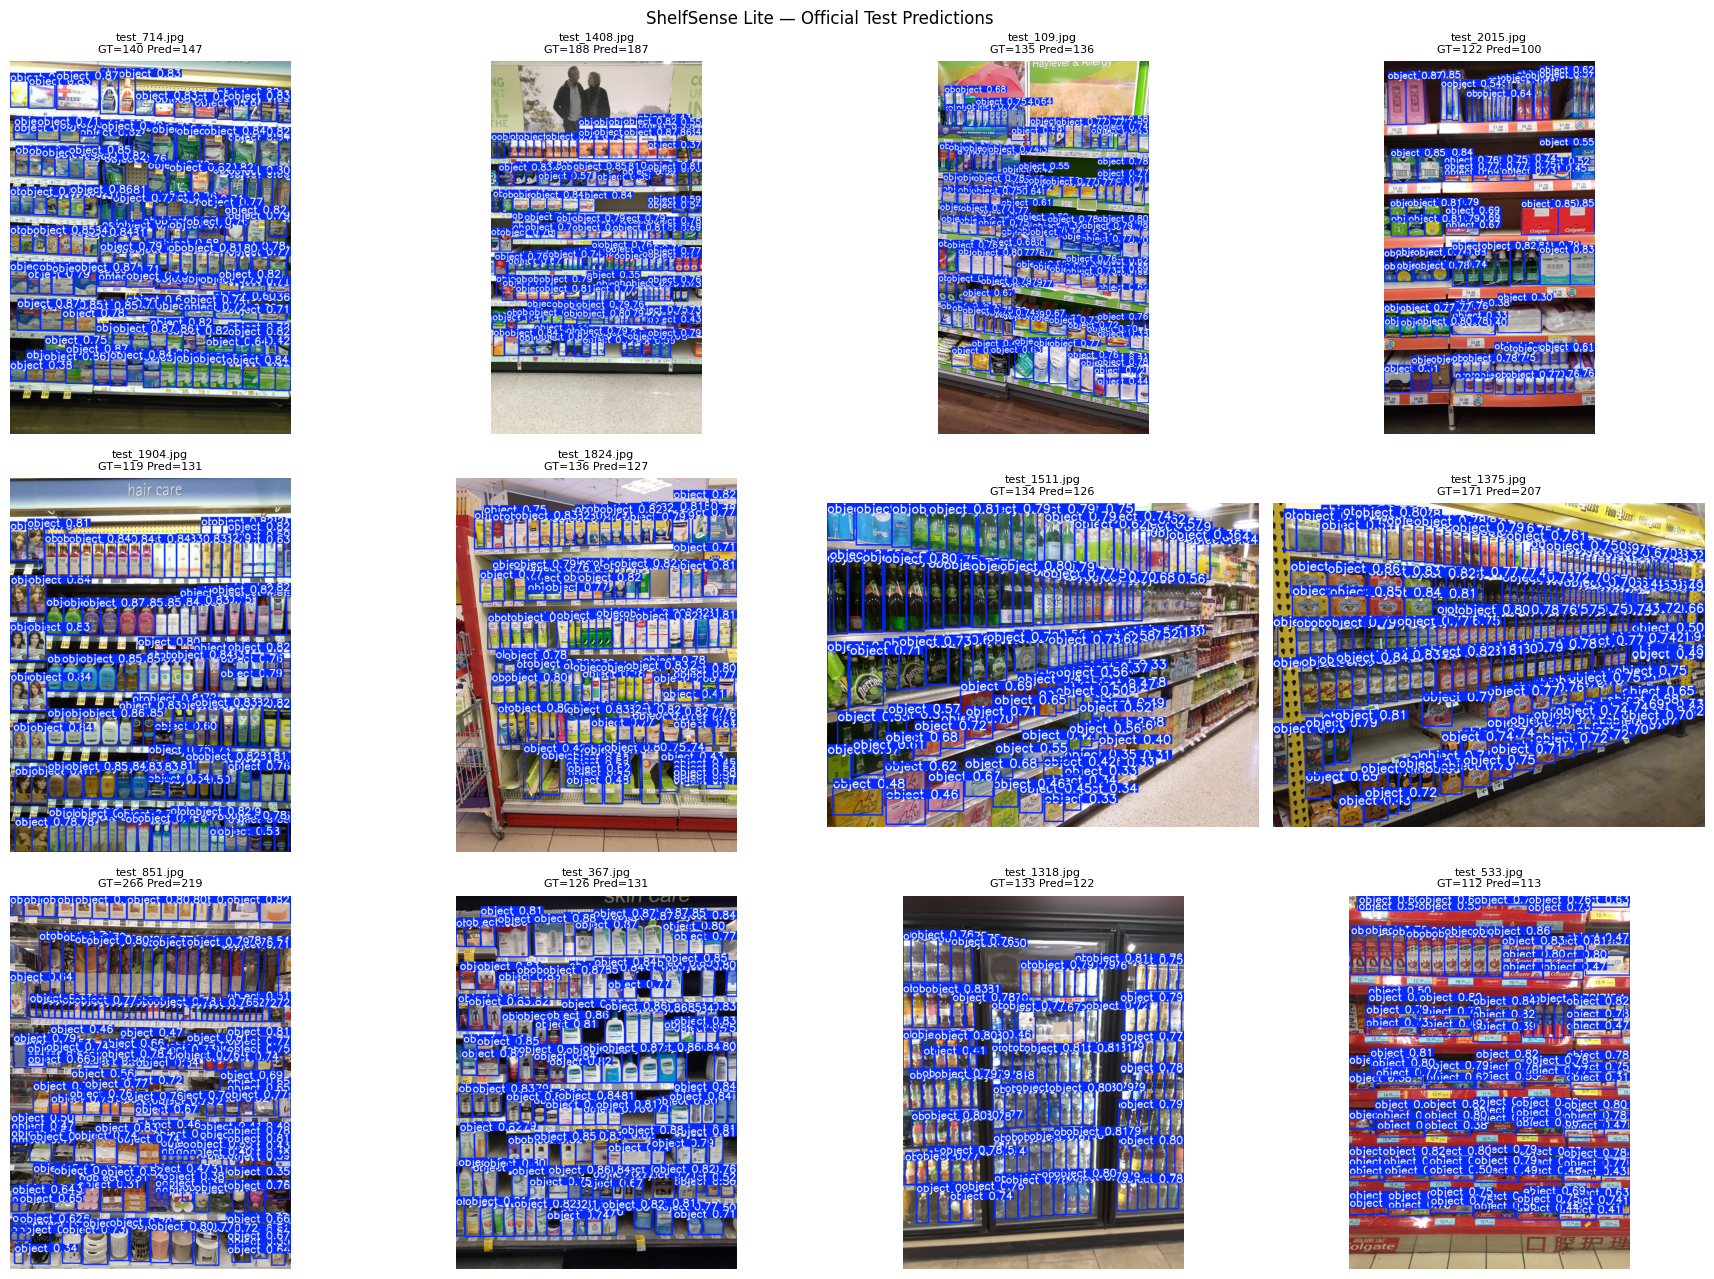

In [18]:

readable_test=[p for p in readable_image_paths("test") if p.name in test_pred]
samples=random.Random(SEED).sample(readable_test,k=min(12,len(readable_test)))
preds=model.predict(source=[str(p) for p in samples],imgsz=960,conf=best_conf,iou=.60,max_det=800,device=DEVICE,half=bool(torch.cuda.is_available()),verbose=False)
fig,axes=plt.subplots(3,4,figsize=(18,13)); qual=[]
for ax,p,r in zip(axes.flat,samples,preds):
    shown=r.plot()[:,:,::-1]; pred_n=0 if r.boxes is None else len(r.boxes); gt_n=int(test_gt[p.name]); qual.append({"image":p.name,"gt_count":gt_n,"pred_count":pred_n,"error":pred_n-gt_n}); ax.imshow(shown); ax.set_title(f"{p.name}\nGT={gt_n} Pred={pred_n}",fontsize=8); ax.axis("off")
plt.suptitle("ShelfSense Lite — Official Test Predictions"); plt.tight_layout(); plt.savefig(ASSET_PRED/"official_test_prediction_grid.png",dpi=170,bbox_inches="tight"); plt.show(); pd.DataFrame(qual).to_csv(REPORT/"test_qualitative_samples.csv",index=False)


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


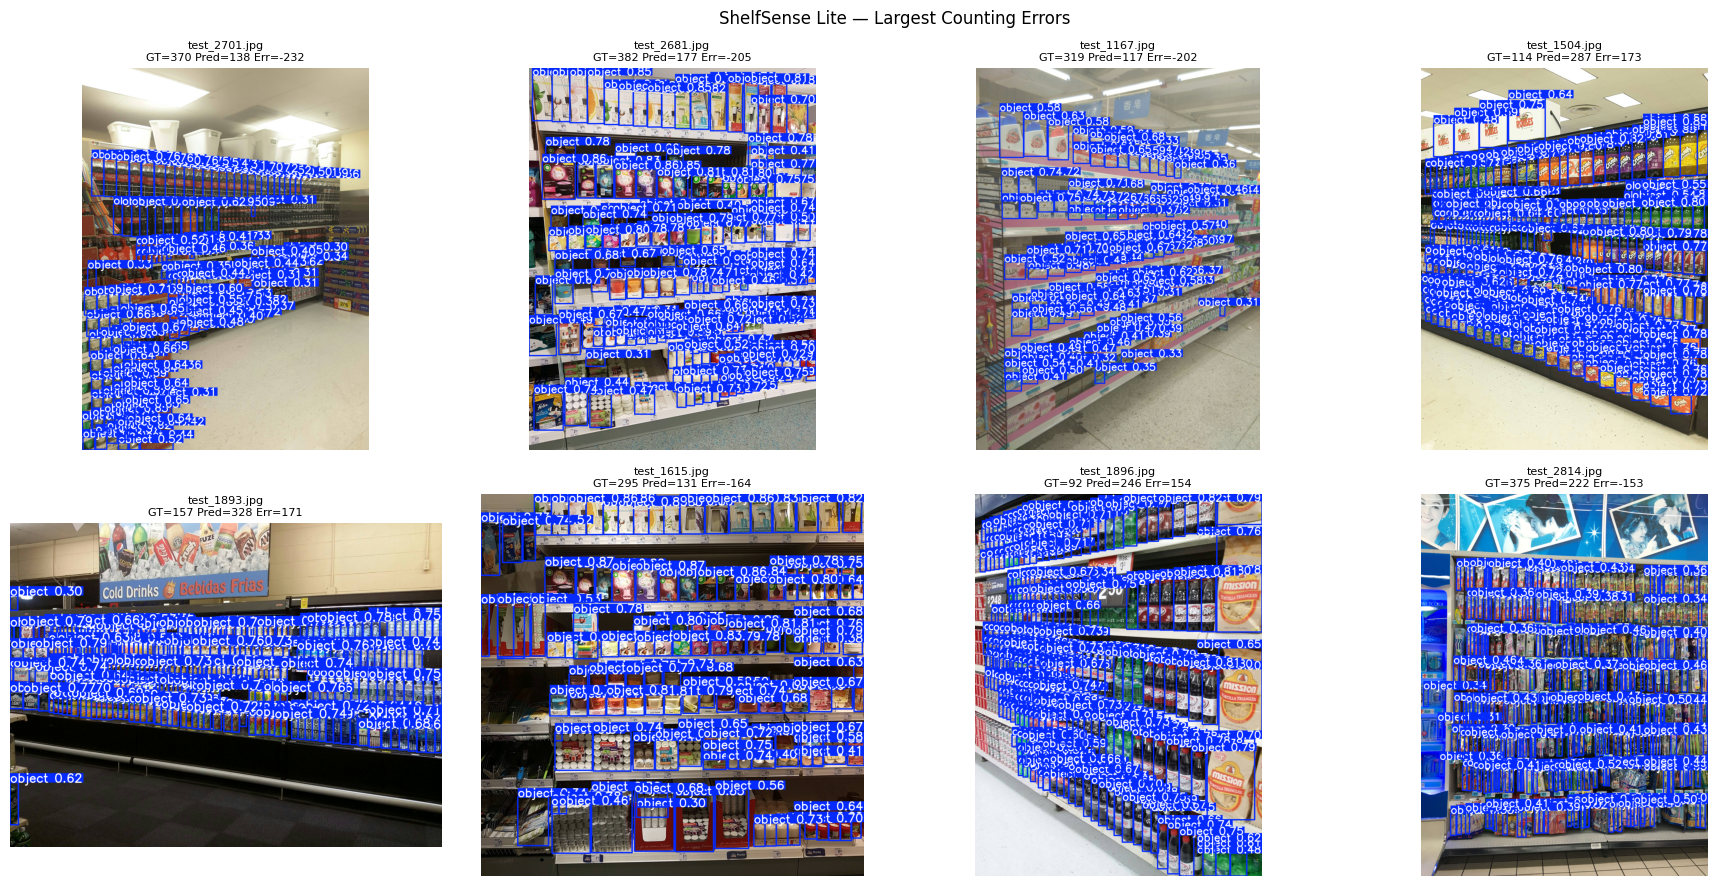

In [19]:

worst_names=count_df.sort_values("abs_error",ascending=False).head(8)["image"].tolist(); worst_paths=[DS/"images"/"test"/n for n in worst_names if (DS/"images"/"test"/n).exists()]
worst_results=model.predict(source=[str(p) for p in worst_paths],imgsz=960,conf=best_conf,iou=.60,max_det=800,device=DEVICE,half=bool(torch.cuda.is_available()),verbose=False)
fig,axes=plt.subplots(2,4,figsize=(18,9))
for ax,p,r in zip(axes.flat,worst_paths,worst_results):
    shown=r.plot()[:,:,::-1]; pred_n=0 if r.boxes is None else len(r.boxes); gt_n=int(test_gt[p.name]); ax.imshow(shown); ax.set_title(f"{p.name}\nGT={gt_n} Pred={pred_n} Err={pred_n-gt_n}",fontsize=8); ax.axis("off")
plt.suptitle("ShelfSense Lite — Largest Counting Errors"); plt.tight_layout(); plt.savefig(ASSET_PRED/"official_test_failure_grid.png",dpi=170,bbox_inches="tight"); plt.show()



## 7. Final scientific summary and portfolio package

`final_summary.json` is the source of truth for README and public claims.


In [20]:

summary={"project":"ShelfSense Lite","portfolio_progress":"11%","dataset":"SKU-110K","task":"single-class dense retail-product object detection","derived_task":"visible-product counting from detections","model":"YOLO11s","input_size":960,"class_names":["object"],"training_history":best_summary,"evaluation_protocol":{"official_split_preserved":True,"validation_max_det":800,"test_max_det":800,"count_threshold_selected_on":"validation only"},"validation_detection":val_report,"official_test_detection":test_report,"counting":{"confidence":best_conf,"official_test":count_test,"error_summary":error_summary},"dataset_audit":audit,"conversion":conversion,"limitations":["Single generic object class only.","No SKU identity recognition.","Visible-product counting is detection-derived.","Occluded and very small products can be missed.","Visible count is not hidden inventory count."]}
(REPORT/"final_summary.json").write_text(json.dumps(summary,indent=2)); print(json.dumps(summary,indent=2))


{
  "project": "ShelfSense Lite",
  "portfolio_progress": "11%",
  "dataset": "SKU-110K",
  "task": "single-class dense retail-product object detection",
  "derived_task": "visible-product counting from detections",
  "model": "YOLO11s",
  "input_size": 960,
  "class_names": [
    "object"
  ],
  "training_history": {
    "best_epoch": 30,
    "epochs_completed": 36,
    "precision": 0.91177,
    "recall": 0.87349,
    "mAP50": 0.93585,
    "mAP50_95": 0.58545
  },
  "evaluation_protocol": {
    "official_split_preserved": true,
    "validation_max_det": 800,
    "test_max_det": 800,
    "count_threshold_selected_on": "validation only"
  },
  "validation_detection": {
    "precision": 0.9119463084161766,
    "recall": 0.8735668457424569,
    "mAP50": 0.9358892967255817,
    "mAP50_95": 0.5866980113205288,
    "max_det": 800,
    "speed_ms": {
      "preprocess": 1.5650236020409694,
      "inference": 14.589159899661094,
      "loss": 0.023230192177803463,
      "postprocess": 6.7590914

In [21]:

PACKAGE=Path("/kaggle/working/shelfsense_11pct_FINAL")
if PACKAGE.exists(): shutil.rmtree(PACKAGE)
for p in [PACKAGE/"models",PACKAGE/"reports",PACKAGE/"assets"/"dataset",PACKAGE/"assets"/"training",PACKAGE/"assets"/"evaluation",PACKAGE/"assets"/"predictions"]: p.mkdir(parents=True,exist_ok=True)
shutil.copy2(FINAL_MODEL,PACKAGE/"models"/"shelfsense_yolo11s_best.pt"); shutil.copy2(ARGS_YAML,PACKAGE/"reports"/"training_args.yaml"); shutil.copy2(data_yaml,PACKAGE/"sku110k.yaml")
for src in REPORT.glob("*"):
    if src.is_file(): shutil.copy2(src,PACKAGE/"reports"/src.name)
for src in ASSET_DATA.glob("*"):
    if src.is_file(): shutil.copy2(src,PACKAGE/"assets"/"dataset"/src.name)
for src in ASSET_TRAIN.glob("*"):
    if src.is_file(): shutil.copy2(src,PACKAGE/"assets"/"training"/src.name)
for src in ASSET_EVAL.glob("*"):
    if src.is_file(): shutil.copy2(src,PACKAGE/"assets"/"evaluation"/src.name)
for src in ASSET_PRED.glob("*"):
    if src.is_file(): shutil.copy2(src,PACKAGE/"assets"/"predictions"/src.name)
zip_path=shutil.make_archive("/kaggle/working/shelfsense_11pct_FINAL","zip",root_dir=str(PACKAGE))
print("=== SHELFSENSE LITE 11% FINAL v3 DONE ===",flush=True); print("[DONE] test mAP50-95:",test_report["mAP50_95"],flush=True); print("[DONE] count MAE:",count_test["MAE"],flush=True); print("[DONE] count RMSE:",count_test["RMSE"],flush=True); print("[DONE] ZIP:",zip_path,flush=True)


=== SHELFSENSE LITE 11% FINAL v3 DONE ===
[DONE] test mAP50-95: 0.591797545318477
[DONE] count MAE: 12.949914821124361
[DONE] count RMSE: 22.97501791165539
[DONE] ZIP: /kaggle/working/shelfsense_11pct_FINAL.zip



# Expected final output

```text
/kaggle/working/shelfsense_11pct_FINAL.zip
```

Inside:

```text
models/
reports/
assets/
  dataset/
  training/
  evaluation/
  predictions/
sku110k.yaml
```

### Save Version checklist

- [ ] input paths verified
- [ ] champion loaded
- [ ] dataset audit completed
- [ ] GT grid generated
- [ ] training curves generated
- [ ] validation metrics printed
- [ ] official test metrics printed
- [ ] counting threshold selected on validation only
- [ ] test MAE / RMSE / bias printed
- [ ] count scatter generated
- [ ] count error histogram generated
- [ ] random prediction grid generated
- [ ] failure-case grid generated
- [ ] final_summary.json written
- [ ] final ZIP exists
